# Basics of Mobile Robotics - Project

## Table of Contents

- [Introduction](#introduction)
    - [Goal of the project](#goal-of-the-project)
    - [Group](#group) 
    - [Demo](#demo)
- [Vision Processing](#vision-processing)
    - [Calibration](#calibration)
        - [Calibration parameters](#calibration-parameters)
        - [Process](#process)
        - [Implementation](#implementation)
    - [ArUco Markers](#aruco-markers)
        - [Implementation](#implementation-1)
    - [Bird's-Eye View Transformation](#birds-eye-view-transformation)
        - [Implementation](#implementation-2)
    - [Obstacle Mapping](#obstacle-mapping)
        - [Implementation](#implementation-3)
- [Filtering](#filtering)
- [Navigation](#navigation)
    - [Global Navigation](#global-navigation)
    - [Local Navigation](#local-navigation)
- [Results](#results)
- [Conclusion](#conclusion)

## Introduction 
This project is part of the course *Basics of Mobile Robotics (MICRO-452)* at EPFL and is initially made by a group of four students. The class is given by Professor Francesco Mondada from [MOBOTS lab](https://www.epfl.ch/labs/mobots/).

### Goal of the project 
This project aims to implement diverse algorithms seen in the course: 
- Autonomous navigation through a specific goal following the optimal path. 
- Keep track of the goal if blind through an extended Kalman filter. 
- Be able to reach any position in the predefined map.
- Unexpected object avoidance. 

### Group
Our team consists of three first-year Master's students in Robotics at EPFL. The workload has been equally separated between members. The final assembly of the code has been done by everyone. 
| Name            | SCIPER | Role                       |
|-----------------|--------|----------------------------|
| Linus  Crugnola | 340864 | Filtering                  |
| Alexis Bollack  | 406474 | Local & Global navigation  |
| Maxime Luyet    | 345770 | Vision                     |

### Demo 
Here you can see a video of the final result. The Thymio reaches the goal successfully. 

[VIDEO]

## Vision processing
The goal of this module is to provide real-time visual information to the navigation system. It is responsible for initializing an occupancy grid used to compute an A* optimal path in the *global_nav* module. To achieve this, the vision module must go through several stages:

1. Acquire a frame from the camera.
2. Compute a bird's-eye view (perpendicular top-down projection) of the environment using ArUco markers.
3. Detect obstacles and initialize the occupancy grid.
4. Extract the robot and goal positions.

To structure this, the system is divided into two classes: Camera and Vision.
This separation allows dedicated handling of the camera stream on one side, and all computer-vision operations on the other. It also improves the clarity of the architecture by isolating specific methods and attributes, ensuring better modularity and encapsulation.

Before implementing these classes, several essential tasks were required, such as camera calibration and ArUco marker generation, both of which are necessary to ensure accurate mapping, detection, and geometric transformations.

### Calibration
The calibration process allows us to obtain the intrinsic parameters of the camera in order to correct lens distortion. To perform this step, we used the [OpenCV](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html) library. 

The method consists of capturing several images of a calibration pattern (typically a chessboard), detecting its corner points, and using these correspondences to estimate how the camera projects 3D points onto the 2D image plane.

#### Calibration parameters  
**Distortion coefficients** are a vector containing: 
- Radial distortion ($k_1$, $k_2$, $k_3$)
- Tangential distortion ($p_1$, $p_2$)

$$D = \begin{pmatrix} k_1 & k_2 & p_1 & p_2 & k_3 \end{pmatrix}$$

**Calibration matrix** is a correction matrix made of intrinsic parameters of the camera: 
- Focal distances ($f_x$, $f_y$)
- Optical center ($c_x$, $c_y$)

$$M = \begin{pmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{pmatrix}$$

#### Process

OpenCV provides all the required tools for this workflow:

[`cv2.findChessboardCorners()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga93efa9b0aa890de240ca32b11253dd4a) – Detects the inner intersections of the chessboard pattern in each calibration image.

[`cv2.cornerSubPix()`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga354e0d7c86d0d9da75de9b9701a9a87e) – Refines the detected corner positions to sub-pixel accuracy for better calibration precision.

[`cv.drawChessboardCorners()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga6a10b0bb120c4907e5eabbcd22319022) – Alternative function allowing to visualize the corner detection. 

[`cv2.calibrateCamera()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga3207604e4b1a1758aa66acb6ed5aa65d) – Computes the intrinsic matrix, distortion coefficients (k₁, k₂, p₁, p₂, k₃), and optionally the rotation and translation vectors of the camera.

[`cv2.getOptimalNewCameraMatrix()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga3207604e4b1a1758aa66acb6ed5aa65d) – Produces an adjusted projection matrix that balances field of view and distortion removal.

[`cv2.undistort()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga69f2545a8b62a6b0fc2ee060dc30559d) – Uses the computed parameters to remove lens distortion from any captured frame.

This calibration procedure provides the intrinsic matrix and distortion vector used in the module to undistort the input frames before extracting ArUco markers and computing the bird's-eye-view transformation.

#### Implementation 

The method `vision.setup()` implements the image distortion correction using the intrinsic parameters obtained after the calibration process:

```python 
h, w = frame.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(CAMERA_MATRIX, CAMERA_COEFFICIENTS, (w, h), 1, (w, h))
self.distortion = newcameramtx
self.roi = roi
frame = cv2.undistort(frame, CAMERA_MATRIX, CAMERA_COEFFICIENTS, None, self.distortion)
x, y, w, h = self.roi
frame = frame[y:y+h, x:x+w]
```

### ArUco Markers

ArUco markers are binary square fiducial markers that can be used for camera pose estimation and object tracking. For this project, we use the **4x4_100 dictionary** from OpenCV, which provides 100 unique markers in a 4×4 grid format. Each marker is 10×10 cm in size and printed at 300 DPI (591×591 pixels) on an A0 paper that defines the working area.

All markers were generated using the script `aruco_generation.py`, following the [OpenCV ArUco detection guide](https://docs.opencv.org/4.x/d5/dae/tutorial_aruco_detection.html).

The system uses six specific markers for different purposes:

**Map Corner Markers** (define the working area):
- **ID 69**: Top-left corner
- **ID 42**: Top-right corner  
- **ID 23**: Bottom-left corner
- **ID 30**: Bottom-right corner

**Dynamic Markers** (track moving elements):
- **ID 78**: Robot marker (attached to the Thymio)
- **ID 53**: Goal marker (target position)

These markers enable the vision system to:
1. Establish a fixed reference frame using the four corner markers.
2. Compute the perspective transformation for the bird's-eye view.
3. Track the robot's position and orientation in real-time.
4. Identify the goal location for path planning.

![Map with ArUco markers](scripts/aruco_markers/img/map_img.png)

#### Implementation 

The ArUco detection system is initialized in the `Vision` class constructor. This setup creates the detector with the appropriate dictionary and parameters:

```python 
def __init__(self):
    # Initialize ArUco dictionary and detector
    self.aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_100)
    self.param = cv2.aruco.DetectorParameters()
    self.detector = cv2.aruco.ArucoDetector(self.aruco_dict, self.param)
```

The detector is then used throughout the vision pipeline to identify markers in each frame and extract their positions and orientations for coordinate transformations and tracking.

### Bird's-Eye View Transformation

To obtain an accurate occupancy grid, a **bird's-eye view** (top-down perpendicular projection) of the map is required. This transformation corrects perspective distortion using the four corner ArUco markers as reference points. The implementation follows the [OpenCV geometric transformations guide](https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html).

#### Implementation

The perspective transformation is implemented through two key steps:

1. **Compute the transformation matrix** using `_get_transform_matrix(corners_dict, width_px, height_px)`:
   - Defines source points from the detected corner marker positions in the camera frame
   - Defines destination points as a perfect rectangle in the output image
   - Computes the transformation matrix using [`cv2.getPerspectiveTransform()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#ga20f62aa3235d869c9956436c870893ae)

2. **Apply the transformation** using [`cv2.warpPerspective()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#gaf73673a7e8e18ec6963e3774e6a94b87):
   - Warps the input frame according to the computed matrix
   - Produces a perfectly perpendicular view of the map

Both operations are performed in the `vision.setup()` method during the initial configuration of the vision system. This setup ensures that all subsequent processing operates on geometrically corrected images, which is essential for accurate obstacle detection and robot localization. 

INSERT IMG BEFORT/AFTER CROP 

### Obstacle Mapping

Once the bird's-eye view is obtained, the system generates an **occupancy grid** (cost map) to represent obstacles in the environment. This grid is used by the global navigation module to compute the optimal A* path. The obstacle detection pipeline follows the [OpenCV image processing tutorials](https://docs.opencv.org/4.x/d2/d96/tutorial_py_table_of_contents_imgproc.html) and implements a multi-step approach:

**Processing Steps:**

1. **Convert to grayscale** – `gray` – Simplifies the image for processing.
2. **Gaussian blur** ([`cv2.GaussianBlur()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gaabe8c836e97159a9193fb0b11ac52cf1)) – `blurred` – Reduces noise.
3. **Adaptive thresholding** ([`cv2.adaptiveThreshold()`](https://docs.opencv.org/4.x/d7/d1b/group__imgproc__misc.html#ga72b913f352e4a1b1b397736707afcde3)) – `binary` – Separates obstacles from free space using local intensity thresholds.
4. **Morphological operations** ([`cv2.morphologyEx()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga67493776e3ad1a3df63883829375201f)) – Cleans up noise with opening and closing operations.
5. **Contour filling** ([`cv2.findContours()`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [`cv2.drawContours()`](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga746c0625f1781f1ffc9056259103edbc)) – `cleaned` – Fills holes inside detected obstacles.
6. **Dilation** ([`cv2.dilate()`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga4ff0f3318642c4f469d0e11f242f3b6c)) – `dilated` – Expands obstacles by the robot's radius to create a safety margin.
7. **Distance transform** ([`cv2.distanceTransform()`](https://docs.opencv.org/4.x/d7/d1b/group__imgproc__misc.html#ga8a0b7fdfcb7a13dde018988ba3a43042)) – `cost_map` – Computes distance to nearest obstacle, creating a gradient cost map with smooth fading borders.

**Step 1-4: Initial Processing and Noise Reduction**

| Grayscale | Gaussian Blur | Adaptive Threshold | Morphological Cleaning |
|:---------:|:-------------:|:------------------:|:----------------------:|
| ![](img/Occupancy%20Grid%20-%20Grayscale.png) | ![](img/Occupancy%20Grid%20-%20Blurred.png) | ![](img/Occupancy%20Grid%20-%20Binary.png) | ![](img/Occupancy%20Grid%20-%20Cleaned.png) |
| `gray ` | `blurred` | `binary` | `cleaned` |

**Step 5-7: Safety Margins and Cost Map Generation**

| Contour Filling + Dilation | Distance Transform | Final Cost Map |
|:---------------------------:|:------------------:|:--------------:|
| ![](img/Occupancy%20Grid%20-%20Dilated.png) | ![](img/fading_border.png) | ![](img/Occupancy%20Grid%20-%20Fading.png) |
| `dilated` | `cost_map` | `fading_border` |

It is also important to precise that between step 4 and 5 we apply a mask converted from real size of the ArUko to pixels to covers the corner if it has not been already done.
```python
 if is_marker_in_corners:
            # Calculate mask size
            # ARUCO_SIZE_CM + Margin (e.g., 2cm)
            mask_size_px = int((ARUCO_SIZE_CM + 2.0) * self.pixels_per_cm)
            # Black mask
            color = 0 
            h, w = binary.shape
            # Top-Left
            cv2.rectangle(binary, (0, 0), (mask_size_px, mask_size_px), color, -1)
            # Top-Right
            cv2.rectangle(binary, (w - mask_size_px, 0), (w, mask_size_px), color, -1)
            # Bottom-Left
            cv2.rectangle(binary, (0, h - mask_size_px), (mask_size_px, h), color, -1)
            # Bottom-Right
            cv2.rectangle(binary, (w - mask_size_px, h - mask_size_px), (w, h), color, -1)
```

#### Implementation

The complete obstacle detection is implemented in the `get_occupancy_grid()` method:

This produces a **cost map** where pixel intensity represents traversal cost: 255 (white) indicates obstacles, 0 (black) represents free space, and intermediate values create a gradient zone that helps the path planner avoid edges.


## Camera and Thymio connexion 

Here we setup the connexion to the other perhiphericals. 

In [1]:
# Get frames to auto-adjust camera and get fps

cv2.namedWindow("output", cv2.WINDOW_NORMAL)

while True:

    ret, frame = cam.get_frame()

    if not ret:
        print("Error: Could not read frame.")
        break

    cv2.imshow("output", frame)

    time.sleep(0.01)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cv2.destroyAllWindows()

NameError: name 'cv2' is not defined

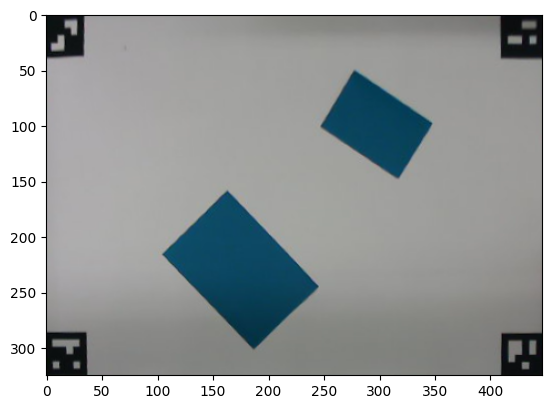

In [ ]:
# Try with cut world function:

ret, frame = cam.get_frame()

if not ret:
    print("Error: Could not read frame.")
    exit(1)

test_crop = vision._cut_frame_to_world(frame)

# cv2.namedWindow("test", cv2.WINDOW_NORMAL)

# while True:

#     cv2.imshow("test", test_crop)

#     if cv2.waitKey(1) & 0xFF == ord('q'):
#         break

# cv2.destroyAllWindows()

test_crop_plt = cv2.cvtColor(test_crop, cv2.COLOR_RGB2BGR)
plt.imshow(test_crop_plt)
plt.show()

In [ ]:
cam.stop()

Camera with ID 1 released, thread stopped


FPS: 78.59
FPS: 79.55
FPS: 79.29
FPS: 79.53
Detected markers: {23: (526.0, 368.0), 69: (18.0, 357.0), 30: (505.0, 44.0), 42: (59.0, 37.0)}
Map size in pixels: width = 446.0 , height = 324.0
Pixels per cm: 4.6947368421052635


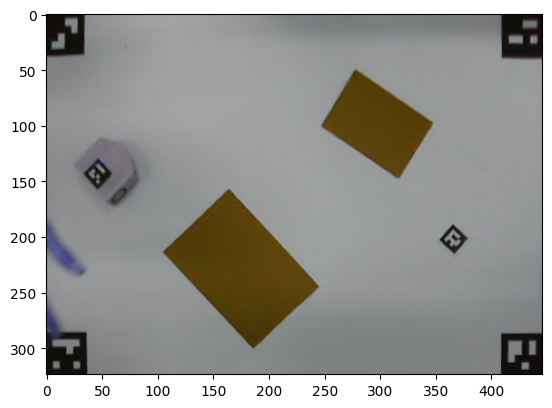

In [ ]:
# Let Camera adjust
cv2.namedWindow("output", cv2.WINDOW_NORMAL)
counter=0
while True:
    # print fps
    time_start = time.time()

    ret, frame = cam.get_frame()

    if not ret:
        print("Error: Could not read frame.")
        break

    cv2.imshow("output", frame)

    time.sleep(0.01)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        
        break

    time_end = time.time()
    fps = 1 / (time_end - time_start)
    counter+=1
    if counter%100==0:
        print(f"FPS: {fps:.2f}")
        counter=0

cv2.destroyAllWindows()

# Initialize vision
test_frame = vision.setup(frame)

plt.imshow(test_frame)

In [ ]:
def draw_pose(img, pose, color):
    x, y, theta = pose
    x = int(x)
    y = int(y)

    # robot center
    cv2.circle(img, (x, y), 5, color, -1)

    # heading line
    x2 = int(x + 20 * np.cos(theta))
    y2 = int(y + 20 * np.sin(theta))
    #cv2.line(img, (x, y), (x2, y2), color, 2)
    cv2.arrowedLine(img, (x, y), (x2, y2), color, thickness=2)

def draw_path(img, path, color):
    for idx in range((len(path))-1):
        # put in correct frame
        y, x = path[idx]
        y_after, x_after = path[idx + 1]
        x = int(x)
        y = int(y)
        x_after = int(x_after)
        y_after = int(y_after)
        cv2.line(img, (x, y), (x_after, y_after), color, 2)

def draw_point(img, point, color):
    x, y = point
    x = int(x)
    y = int(y)
    cv2.circle(img, (x, y), 7, color, -1)

In [ ]:
cam.stop()

Camera with ID 4 released, thread stopped


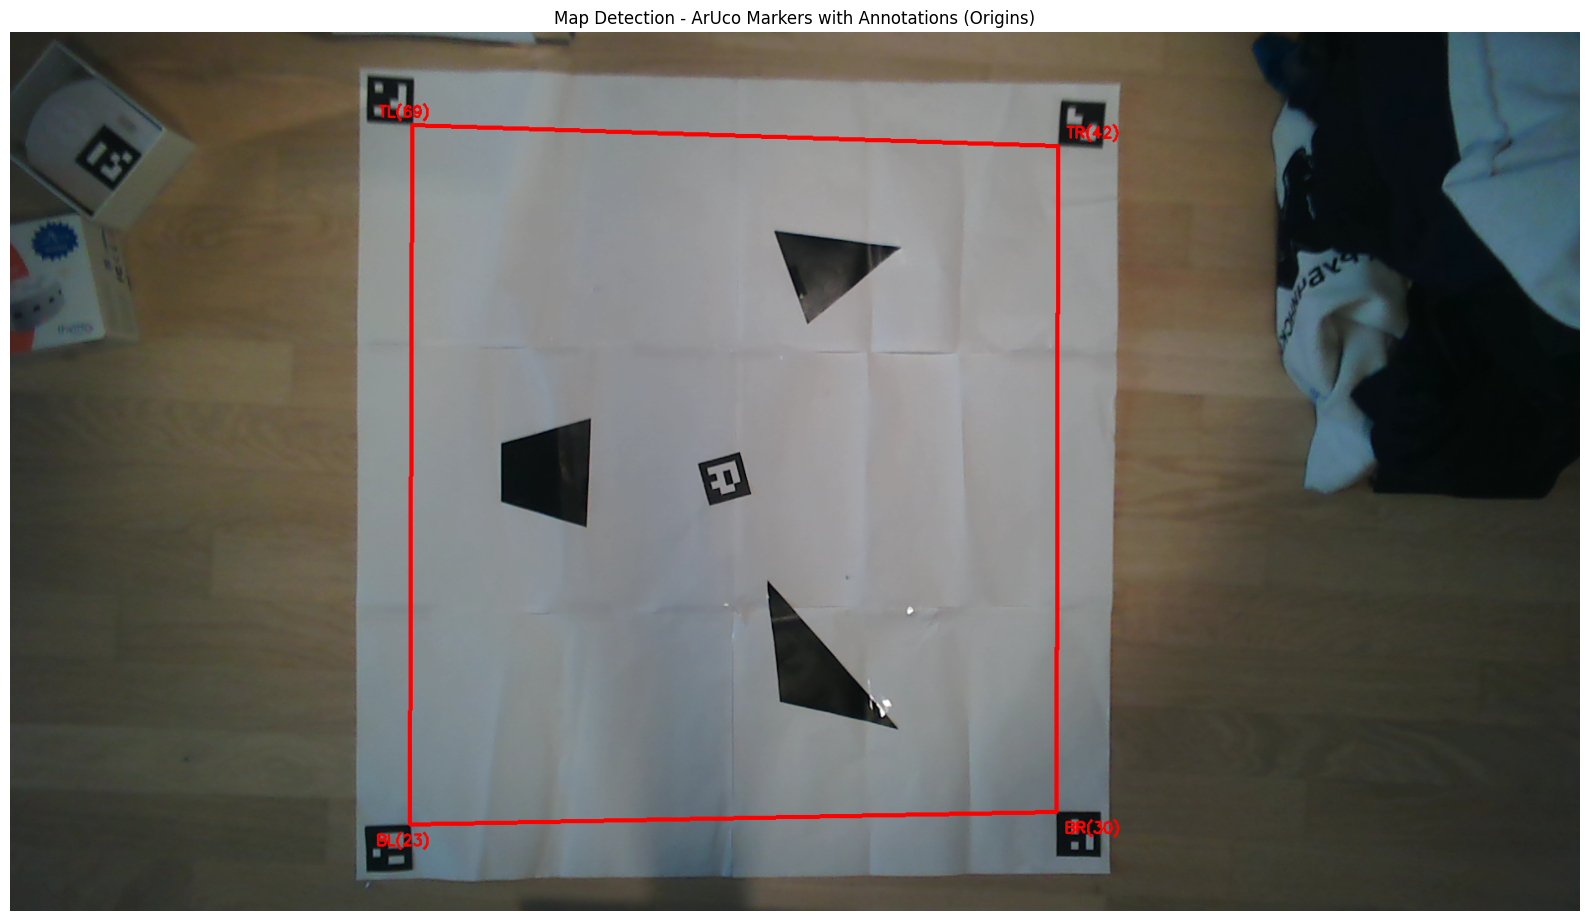

Detected ArUco marker origin positions (Top-Left corner):
  TL (69): (481.0, 111.0)
  TR (42): (1254.0, 136.0)
  BL (23): (478.0, 948.0)
  BR (30): (1252.0, 933.0)


In [ ]:
#============================================
#Test of map detection with aruco markers
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np
from src import utils

# Capture frame
before_map_crop = vision._get_frame()

if before_map_crop is not None:
    # Create a copy for drawing (before detection modifies the frame)
    frame_with_markers = before_map_crop.copy()
    
    # Detect ArUco markers (this will draw on the copy)
    img, corner_pos = vision._detect_map_markers(frame_with_markers)
    
    if corner_pos is not None:
        # Extract the 4 corner markers from dictionary in correct order [TL, TR, BL, BR]
        corners_array = np.array([
            corner_pos[69],  # TL
            corner_pos[42],  # TR
            corner_pos[23],  # BL
            corner_pos[30]   # BR
        ])
        
        # Draw red borders connecting the 4 corner markers using utils
        img = utils.draw_red_line_in_image(corners_array, img)
        
        # Convert BGR to RGB for matplotlib
        frame_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the result
        plt.figure(figsize=(16, 10))
        plt.imshow(frame_rgb)
        plt.title("Map Detection - ArUco Markers with Annotations (Origins)")
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        # Print marker positions (origins = top-left corners)
        print("Detected ArUco marker origin positions (Top-Left corner):")
        for marker_id in [69, 42, 23, 30]:
            if marker_id in corner_pos:
                x, y = corner_pos[marker_id]
                marker_name = {69: "TL", 42: "TR", 23: "BL", 30: "BR"}[marker_id]
                print(f"  {marker_name} ({marker_id}): ({x:.1f}, {y:.1f})")
        
    else:
        print("Failed to detect all ArUco markers!")
        print("Make sure all 6 markers are visible: 69, 42, 23, 30 (corners), 78 (robot), 53 (goal)")
else:
    print("Failed to capture frame")

In [ ]:
birds_eye_view = vision.get_birds_eye_view()
#robot_pose = vision.get_robot_position(birdseye_view=birds_eye_view)
print("pixels_per_cm:", vision.pixels_per_cm)
occupancy_grid = vision.detect_obstacles(birds_eye_view,pixels_per_cm=vision.pixels_per_cm)
# Print statistics
total_cells = occupancy_grid.size
obstacle_cells = np.sum(occupancy_grid)
free_cells = total_cells - obstacle_cells
obstacle_percentage = (obstacle_cells / total_cells) * 100

print(f"\n✓ Occupancy grid generated successfully!")
print(f"  Grid size: {occupancy_grid.shape[1]} x {occupancy_grid.shape[0]} cells")
print(f"  Total cells: {total_cells}")
print(f"  Obstacle cells: {-obstacle_cells} ({-obstacle_percentage:.1f}%)")
print(f"  Free cells: {free_cells} ({100+obstacle_percentage:.1f}%)")


pixels_per_cm: 10.901408450704226
Dilation kernel size (pixels): 119

✓ Occupancy grid generated successfully!
  Grid size: 773 x 838 cells
  Total cells: 647774
  Obstacle cells: 168256 (26.0%)
  Free cells: 816030 (74.0%)


### Test Global path

### Test Kalman

In [ ]:
# 1- Kalman init state
Y_map_size = 908
robot_pose = vision.get_robot_position(birdseye_view=vision.get_birds_eye_view())
# add theta manually
robot_pose = (int(robot_pose[1]), int(robot_pose[0]), 0)
robot_pose_transformed = (robot_pose[0], Y_map_size - robot_pose[1], -robot_pose[2])
kalman.init_state(robot_pose_transformed)

# 2 - Move robot
Control.set_speed(100,100)
time.sleep(1)
Control.set_speed(0,0)

# 3- Kalman predict and update
left_speed, right_speed = robot_get_speed()
predicted_state = kalman.predict(right_speed_m=right_speed, left_speed_m=left_speed, dt=1.0, verbose=True)

# Capture new pose
birds_eye_view = vision.get_birds_eye_view()
measured_pose = vision.get_robot_position(birdseye_view=birds_eye_view)
measured_pose = (int(measured_pose[1]), int(measured_pose[0]), np.pi/2)
measured_pose_transformed = (measured_pose[0], Y_map_size - measured_pose[1], -measured_pose[2])

updated_state = kalman.update(measured_pose_transformed, verbose=True)
updated_state_transformed = (updated_state[0], Y_map_size - updated_state[1], -updated_state[2])